# Laboratorio de Machine Learning: clasificación de frijoles secos

**Guía ejecutiva y técnica para recorrer, interpretar y exponer el proyecto.**

El objetivo es predecir la variedad de un grano de frijol seco a partir de sus mediciones geométricas. El trabajo organiza el análisis con **CRISP-DM**, promueve la reproducibilidad con **TDSP** y distribuye la colaboración con **Scrum ML**.

## Equipo y guía de exposición por rol

| Rol e integrante | Sección que presenta | Aporte que debe explicar |
|---|---|---|
| **Product Owner — Sergio Luis Pantoja Lasso** | Contexto, objetivo y conclusiones | Necesidad que se busca apoyar, valor esperado, criterios para comparar modelos y validación de la decisión final. |
| **Scrum Master — Luis Gerardo Restrepo Arredondo** | Organización del trabajo | Cómo se propone dividir el backlog en sprints, dar seguimiento a bloqueos y revisar los criterios de terminado; no atribuir reuniones no registradas. |
| **Data Engineer / Analyst — Dilmer Gutierrez** | Carga, calidad, limpieza y EDA | Procedencia del conjunto, hallazgos de calidad, distribución de variedades y qué muestran las gráficas. |
| **ML Engineer — Andres David Bolañoz Paz** | Partición reproducible y baseline | Separación entrenamiento/prueba, prevención de fuga de información y función de la regresión logística como referencia. |
| **ML Engineer — Eliana Ordoñez Candimance** | Random Forest y evaluación | Modelo alternativo, métricas por clase, matriz de confusión e interpretación prudente de variables importantes. |

> Esta distribución es una **propuesta para preparar la exposición**, basada en los roles acordados. No representa por sí sola evidencia de que cada tarea ya fue ejecutada o validada por su responsable.

## Cómo recorrer el notebook

- Ejecuta las celdas en orden, de arriba hacia abajo. En VS Code, selecciona el kernel del proyecto y usa **Shift+Enter** para ejecutar una celda y avanzar a la siguiente.
- Lee la explicación antes de ejecutar cada bloque y comenta el resultado que aparece debajo; no es necesario volver a ejecutar todo si solo estás preparando la exposición.
- La primera carga puede necesitar conexión a internet para descargar el conjunto desde UCI. Las gráficas y métricas se guardan en `outputs/reports/` y el modelo en `outputs/models/`.

## Ruta del laboratorio y responsable de exposición

1. **Comprender el negocio — Sergio (Product Owner):** explicar la necesidad que se busca apoyar y qué haría útil una clasificación confiable.
2. **Organizar el trabajo — Luis (Scrum Master):** explicar el flujo propuesto de sprints y cómo se hace seguimiento; consultar la sección Scrum siguiente.
3. **Conocer y preparar los datos — Dilmer (Data Engineer / Analyst):** presentar fuente, calidad, limpieza, distribución y partición.
4. **Construir el baseline — Andres (ML Engineer):** justificar la partición reproducible y explicar la regresión logística como referencia.
5. **Comparar y analizar errores — Eliana (ML Engineer):** explicar Random Forest, métricas por clase, matriz de confusión e importancia de variables.
6. **Cerrar y validar — Sergio con el equipo:** relacionar resultados con los criterios de aceptación y acordar próximos pasos, sin presentar la elección provisional como definitiva.

**Fuente de datos:** [Dry Bean Dataset — UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/602/dry+bean+dataset).

## Aporte del Scrum Master: organizar y dar visibilidad

**Responsable de exposición: Luis Gerardo Restrepo Arredondo.** Su aporte es facilitar la coordinación, hacer visibles prioridades y bloqueos, y ayudar al equipo a revisar los criterios de terminado; no reemplaza las decisiones de producto ni las responsabilidades técnicas.

La secuencia siguiente es una **propuesta de organización** basada en el backlog del proyecto, no un registro de sprints o reuniones ya realizados. Las fechas, acuerdos y bloqueos reales deben completarse con el equipo.

| Sprint propuesto | Objetivo | Elementos relacionados | Revisión al cierre |
|---|---|---|---|
| 1 — Datos | Trazar la fuente, revisar calidad, limpiar duplicados y entender las clases. | PB-01, PB-02 | Confirmar que el conjunto preparado y sus hallazgos son reproducibles. |
| 2 — Modelado | Entrenar baseline y alternativa con la misma partición y comparar resultados. | PB-03, PB-04, PB-05 | Revisar métricas, errores por clase y decisión pendiente del Product Owner. |
| 3 — Entrega | Guardar el modelo, documentar la ejecución y preparar la exposición. | PB-06, PB-07, PB-08 | Validar la Definition of Done y dejar explícitos los pendientes. |

**Guion del Scrum Master:** presentar cómo se prioriza el trabajo, cómo el equipo reportaría avances y bloqueos en el Daily Scrum, y cómo la revisión y retrospectiva convertirían resultados y dificultades en acciones. El plan detallado está en `outputs/reports/scrum_ml.md`; los registros personales y fechas deben basarse en hechos del equipo.

In [1]:
from pathlib import Path
import io
import json
import urllib.request
import zipfile

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.io import arff
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw" / "Dry_Bean_Dataset.arff"
REPORTS_DIR = PROJECT_ROOT / "outputs" / "reports"
MODELS_DIR = PROJECT_ROOT / "outputs" / "models"
UCI_ARCHIVE_URL = "https://archive.ics.uci.edu/static/public/602/dry+bean+dataset.zip"
RANDOM_STATE = 42

for directory in (RAW_DATA_PATH.parent, REPORTS_DIR, MODELS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print(f"Carpeta del proyecto: {PROJECT_ROOT}")
print(f"Semilla de reproducibilidad: {RANDOM_STATE}")

Carpeta del proyecto: D:\MAESTRIA UAO\GESTIONDEPROYECTOENIAYCD\laboratorio1\laboratorio_drybean_ml
Semilla de reproducibilidad: 42


## Paso 1 — Cargar los datos reales | Dilmer Gutierrez

El conjunto contiene mediciones de forma y tamaño calculadas a partir de imágenes. Si el archivo original no está en `data/raw/`, se descarga desde UCI y se extrae el ARFF. La columna `Class` llega codificada como bytes, por lo que la convertimos a texto para facilitar el análisis.

In [2]:
if not RAW_DATA_PATH.exists():
    request = urllib.request.Request(
        UCI_ARCHIVE_URL,
        headers={"User-Agent": "DryBeanMLLab/1.0"},
    )
    with urllib.request.urlopen(request, timeout=60) as response:
        archive_bytes = response.read()
    with zipfile.ZipFile(io.BytesIO(archive_bytes)) as archive:
        arff_member = "DryBeanDataset/Dry_Bean_Dataset.arff"
        RAW_DATA_PATH.write_bytes(archive.read(arff_member))

with RAW_DATA_PATH.open("r", encoding="utf-8") as source:
    records, metadata = arff.loadarff(source)

df = pd.DataFrame.from_records(records)
df["Class"] = df["Class"].map(
    lambda value: value.decode("utf-8") if isinstance(value, bytes) else str(value)
)

print(f"Dimensiones originales: {df.shape[0]:,} filas x {df.shape[1]} columnas")
display(df.head())

Dimensiones originales: 13,611 filas x 17 columnas


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395.0,610.291,208.178117,173.888747,1.197191,0.549812,28715.0,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734.0,638.018,200.524796,182.734419,1.097356,0.411785,29172.0,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380.0,624.110,212.826130,175.931143,1.209713,0.562727,29690.0,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008.0,645.884,210.557999,182.516516,1.153638,0.498616,30724.0,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140.0,620.134,201.847882,190.279279,1.060798,0.333680,30417.0,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


## Paso 2 — Comprensión y calidad de los datos | Dilmer Gutierrez

`shape` muestra el tamaño del conjunto, los tipos ayudan a detectar columnas inesperadas y `describe` resume las variables numéricas. Antes de entrenar, también contamos faltantes y registros duplicados.

In [3]:
print("Tipos de datos:")
display(df.dtypes.rename("tipo").to_frame())

missing_by_column = df.isna().sum().sort_values(ascending=False)
missing_total = int(missing_by_column.sum())
duplicate_count = int(df.duplicated().sum())
print(f"Valores faltantes totales: {missing_total}")
print(f"Filas duplicadas completas: {duplicate_count}")

display(df.describe().T.round(2))

Tipos de datos:


,tipo
Area,float64
Perimeter,float64
MajorAxisLength,float64
MinorAxisLength,float64
AspectRation,float64
Eccentricity,float64
ConvexArea,float64
EquivDiameter,float64
Extent,float64
Solidity,float64


Valores faltantes totales: 0
Filas duplicadas completas: 68


,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.28,29324.10,20420.00,36328.00,44652.00,61332.00,254616.00
Perimeter,13611.0,855.28,214.29,524.74,703.52,794.94,977.21,1985.37
MajorAxisLength,13611.0,320.14,85.69,183.60,253.30,296.88,376.50,738.86
MinorAxisLength,13611.0,202.27,44.97,122.51,175.85,192.43,217.03,460.20
AspectRation,13611.0,1.58,0.25,1.02,1.43,1.55,1.71,2.43
Eccentricity,13611.0,0.75,0.09,0.22,0.72,0.76,0.81,0.91
ConvexArea,13611.0,53768.20,29774.92,20684.00,36714.50,45178.00,62294.00,263261.00
EquivDiameter,13611.0,253.06,59.18,161.24,215.07,238.44,279.45,569.37
Extent,13611.0,0.75,0.05,0.56,0.72,0.76,0.79,0.87
Solidity,13611.0,0.99,0.00,0.92,0.99,0.99,0.99,0.99


## Paso 3 — Limpiar duplicados y revisar las clases | Dilmer Gutierrez

Se eliminan únicamente filas idénticas. La gráfica de barras muestra cuántos ejemplos tiene cada variedad. Si las clases tienen tamaños diferentes, Accuracy puede ocultar un bajo desempeño en clases menos frecuentes; por eso también evaluaremos F1 macro y métricas por clase.

Filas después de retirar duplicados: 13,543
Clases: 7
Razón clase más frecuente / menos frecuente: 6.79


,cantidad
Class,
DERMASON,3546
SIRA,2636
SEKER,2027
HOROZ,1860
CALI,1630
BARBUNYA,1322
BOMBAY,522


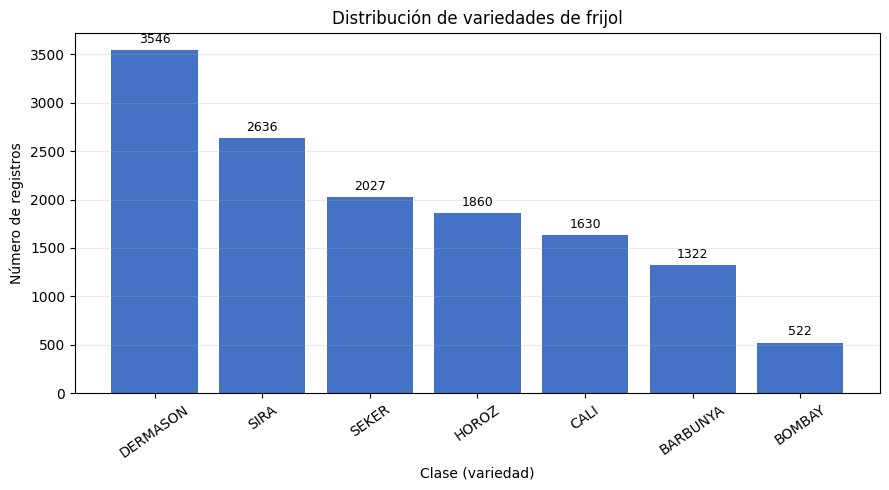

In [4]:
df_clean = df.drop_duplicates().copy()
class_counts = df_clean["Class"].value_counts()
class_ratio = float(class_counts.max() / class_counts.min())

print(f"Filas después de retirar duplicados: {len(df_clean):,}")
print(f"Clases: {len(class_counts)}")
print(f"Razón clase más frecuente / menos frecuente: {class_ratio:.2f}")
display(class_counts.rename("cantidad").to_frame())

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(class_counts.index, class_counts.values, color="#4472C4")
ax.bar_label(bars, padding=3, fontsize=9)
ax.set_title("Distribución de variedades de frijol")
ax.set_xlabel("Clase (variedad)")
ax.set_ylabel("Número de registros")
ax.tick_params(axis="x", rotation=35)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(REPORTS_DIR / "distribucion_clases.png", dpi=150, bbox_inches="tight")
plt.show()

### EDA — Distribución de las medidas | Dilmer Gutierrez

Los histogramas permiten comparar la forma de algunas variables geométricas. Por ejemplo, el área suele tener una escala y asimetría diferentes a las razones de forma; esto justifica revisar estadísticas antes de elegir transformaciones o modelos.

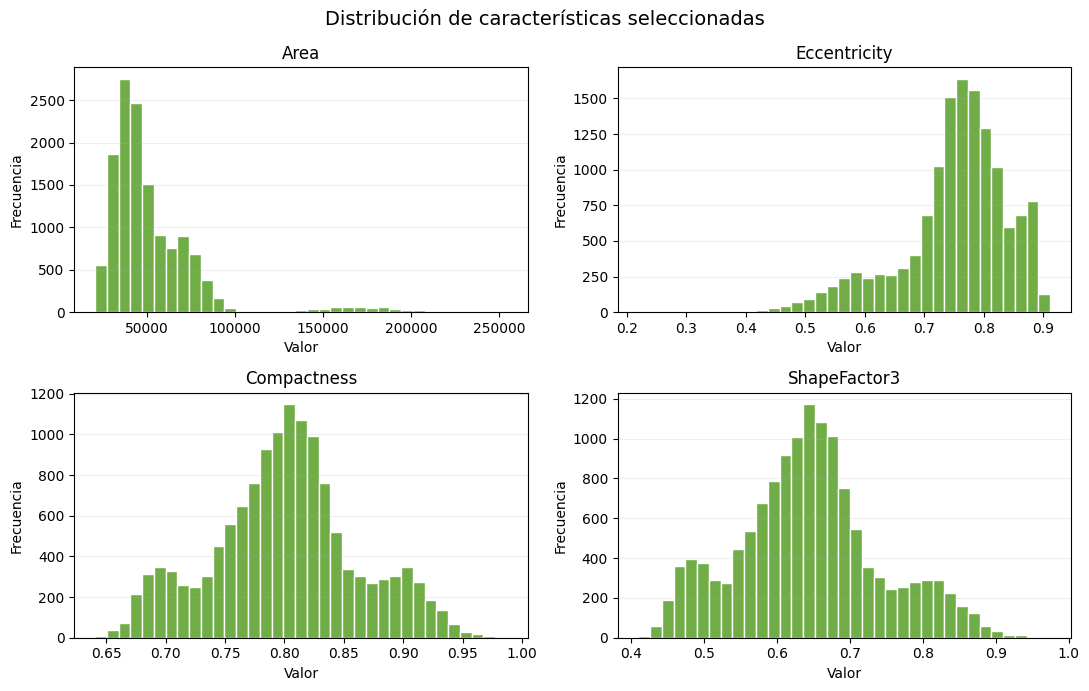

In [5]:
hist_features = ["Area", "Eccentricity", "Compactness", "ShapeFactor3"]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for feature, ax in zip(hist_features, axes.ravel()):
    ax.hist(df_clean[feature], bins=35, color="#70AD47", edgecolor="white")
    ax.set_title(feature)
    ax.set_xlabel("Valor")
    ax.set_ylabel("Frecuencia")
    ax.grid(axis="y", alpha=0.2)
fig.suptitle("Distribución de características seleccionadas", fontsize=14)
fig.tight_layout()
fig.savefig(REPORTS_DIR / "distribucion_caracteristicas.png", dpi=150, bbox_inches="tight")
plt.show()

### EDA — Correlación entre características | Dilmer Gutierrez

El mapa de calor muestra correlaciones lineales entre algunas medidas de tamaño y forma. Correlación no significa causalidad; las variables geométricas relacionadas pueden aportar información redundante y deben interpretarse junto con el contexto del problema.

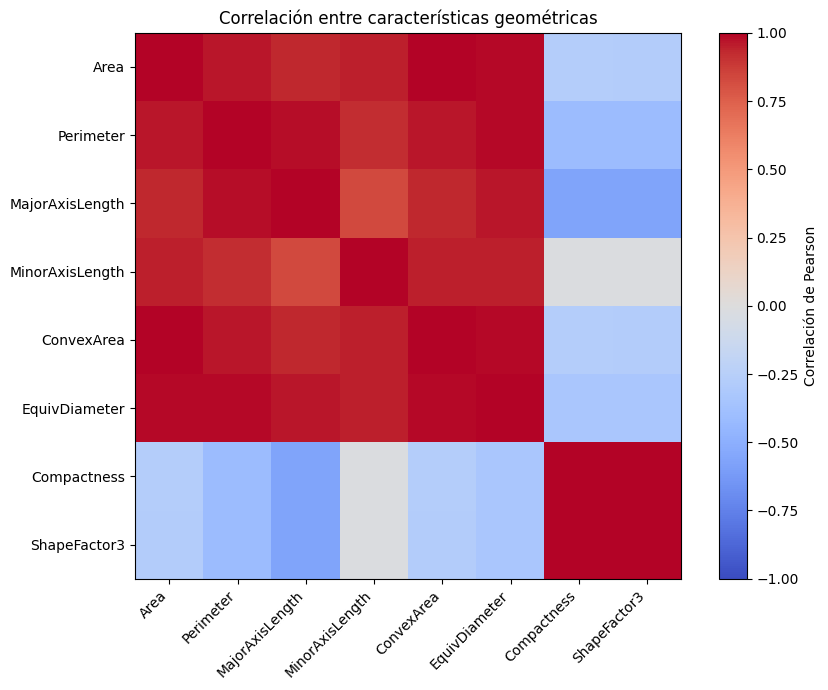

In [6]:
correlation_features = [
    "Area", "Perimeter", "MajorAxisLength", "MinorAxisLength",
    "ConvexArea", "EquivDiameter", "Compactness", "ShapeFactor3",
]
correlation = df_clean[correlation_features].corr()

fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(correlation_features)), labels=correlation_features, rotation=45, ha="right")
ax.set_yticks(range(len(correlation_features)), labels=correlation_features)
ax.set_title("Correlación entre características geométricas")
fig.colorbar(image, ax=ax, label="Correlación de Pearson")
fig.tight_layout()
fig.savefig(REPORTS_DIR / "correlacion_caracteristicas.png", dpi=150, bbox_inches="tight")
plt.show()

## Paso 4 — Separar predictores y objetivo | Dilmer Gutierrez y Andres David Bolañoz Paz

`X` contiene las 16 medidas geométricas; `y` contiene la etiqueta `Class`. La partición 80/20 reserva datos no vistos para la evaluación. `stratify=y` mantiene aproximadamente la misma proporción de variedades en entrenamiento y prueba.

In [7]:
X = df_clean.drop(columns="Class")
y = df_clean["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"Entrenamiento: {len(X_train):,} filas")
print(f"Prueba: {len(X_test):,} filas")
print(f"Predictoras: {X_train.shape[1]}")

Entrenamiento: 10,834 filas
Prueba: 2,709 filas
Predictoras: 16


## Paso 5 — Entrenar el baseline: regresión logística | Andres David Bolañoz Paz

El baseline proporciona una referencia sencilla para juzgar modelos más complejos. Estandarizamos las variables dentro de un `Pipeline`, de modo que el escalamiento se ajuste solo con los datos de entrenamiento y no filtre información del conjunto de prueba.

In [8]:
baseline_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
)
baseline_model.fit(X_train, y_train)
y_pred_baseline = baseline_model.predict(X_test)

baseline_metrics = {
    "accuracy": float(accuracy_score(y_test, y_pred_baseline)),
    "f1_macro": float(f1_score(y_test, y_pred_baseline, average="macro")),
}
print(f"Accuracy baseline: {baseline_metrics['accuracy']:.4f}")
print(f"F1 macro baseline: {baseline_metrics['f1_macro']:.4f}")
print("Reporte por clase:")
display(pd.DataFrame(classification_report(
    y_test, y_pred_baseline, output_dict=True, zero_division=0
)).T.round(3))

Accuracy baseline: 0.9192
F1 macro baseline: 0.9302
Reporte por clase:


,precision,recall,f1-score,support
BARBUNYA,0.925,0.891,0.908,265.000
BOMBAY,1.000,1.000,1.000,104.000
CALI,0.911,0.942,0.926,326.000
DERMASON,0.927,0.907,0.917,709.000
HOROZ,0.964,0.944,0.954,372.000
SEKER,0.930,0.943,0.936,406.000
SIRA,0.858,0.884,0.871,527.000
accuracy,0.919,0.919,0.919,0.919
macro avg,0.931,0.930,0.930,2709.000
weighted avg,0.920,0.919,0.919,2709.000


## Paso 6 — Entrenar el modelo alternativo: Random Forest | Eliana Ordoñez Candimance

Random Forest combina muchos árboles de decisión y no necesita estandarización. Se fija la semilla para reproducir el experimento y se usa `class_weight="balanced"` como apoyo ante diferencias en la frecuencia de clases.

In [9]:
forest_model = RandomForestClassifier(
    n_estimators=200,
    random_state=RANDOM_STATE,
    class_weight="balanced",
    n_jobs=-1,
)
forest_model.fit(X_train, y_train)
y_pred_forest = forest_model.predict(X_test)

forest_metrics = {
    "accuracy": float(accuracy_score(y_test, y_pred_forest)),
    "f1_macro": float(f1_score(y_test, y_pred_forest, average="macro")),
}
metrics = {
    "Regresi?n log?stica (baseline)": baseline_metrics,
    "Random Forest": forest_metrics,
}
metrics_table = pd.DataFrame(metrics).T
display(metrics_table.round(4))
print(
    "Diferencia de F1 macro (Random Forest - baseline): "
    f"{forest_metrics['f1_macro'] - baseline_metrics['f1_macro']:+.4f}"
)

,accuracy,f1_macro
Regresi?n log?stica (baseline),0.9192,0.9302
Random Forest,0.9192,0.9303


Diferencia de F1 macro (Random Forest - baseline): +0.0001


## Paso 7 — Evaluar errores con la matriz de confusión | Eliana Ordoñez Candimance

La diagonal representa predicciones correctas; las celdas fuera de ella muestran confusiones entre variedades. Revisaremos el par con mayor suma de errores mutuos. La gráfica describe esta partición de prueba, no demuestra por sí sola el motivo físico de la confusión.

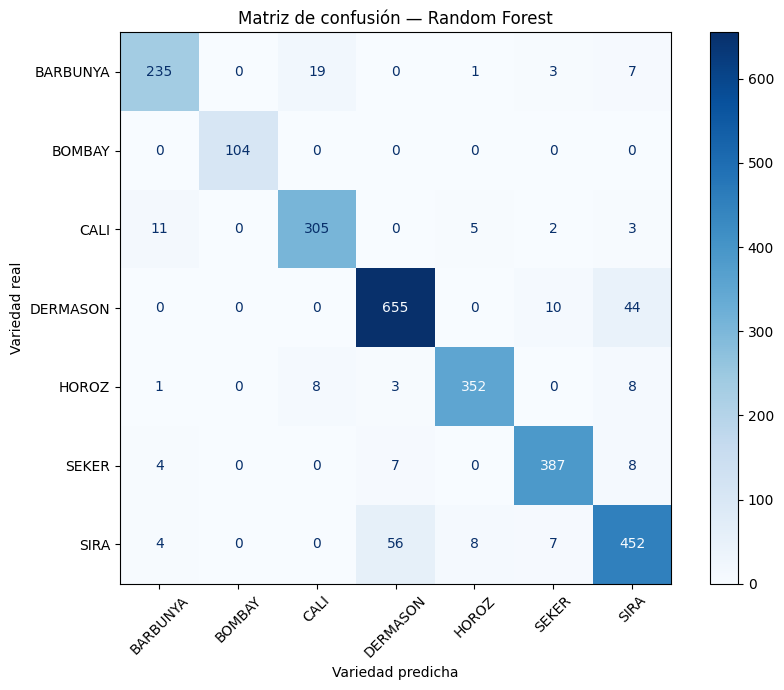

Par con más confusiones mutuas: DERMASON y SIRA (100 errores sumados en ambas direcciones).


In [10]:
class_labels = sorted(y.unique())
confusion = confusion_matrix(y_test, y_pred_forest, labels=class_labels)

fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_forest,
    labels=class_labels,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45,
    ax=ax,
)
ax.set_title("Matriz de confusión — Random Forest")
ax.set_xlabel("Variedad predicha")
ax.set_ylabel("Variedad real")
fig.tight_layout()
fig.savefig(REPORTS_DIR / "matriz_confusion_random_forest.png", dpi=150, bbox_inches="tight")
plt.show()

errors = confusion.copy()
np.fill_diagonal(errors, 0)
mutual_errors = errors + errors.T
np.fill_diagonal(mutual_errors, 0)
row, column = np.unravel_index(np.argmax(mutual_errors), mutual_errors.shape)
print(
    f"Par con más confusiones mutuas: {class_labels[row]} y {class_labels[column]} "
    f"({mutual_errors[row, column]} errores sumados en ambas direcciones)."
)

## Paso 8 — Interpretar la importancia de variables | Eliana Ordoñez Candimance y Dilmer Gutierrez

Random Forest estima cuánto contribuye cada variable a sus divisiones. La importancia ayuda a describir el modelo, pero **no** prueba que una medida cause la variedad. Contrástala con conocimiento del dominio y otros análisis antes de sacar conclusiones.

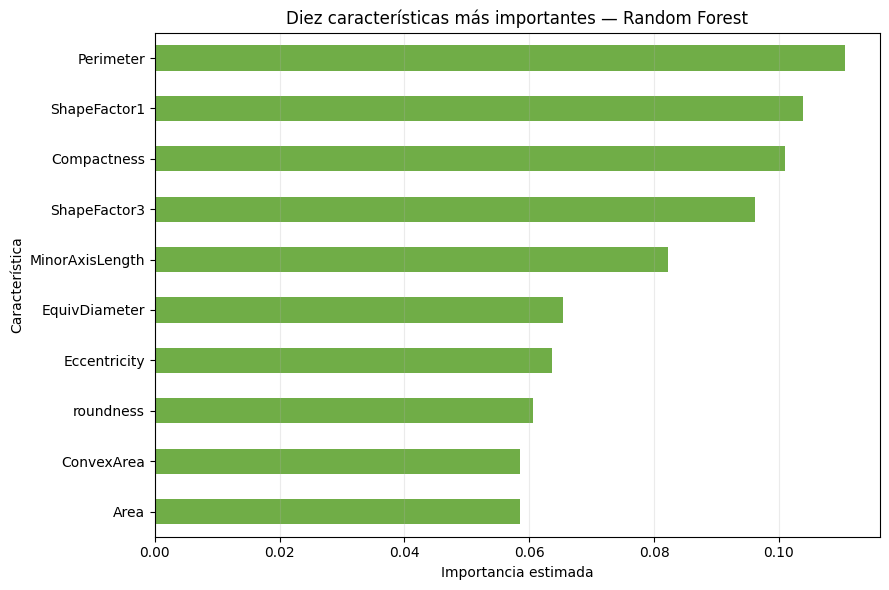

,característica,importancia
1,Perimeter,0.1107
12,ShapeFactor1,0.1038
11,Compactness,0.1010
14,ShapeFactor3,0.0962
3,MinorAxisLength,0.0823
7,EquivDiameter,0.0654
5,Eccentricity,0.0636
10,roundness,0.0606
6,ConvexArea,0.0585
0,Area,0.0584


In [11]:
feature_importance = pd.DataFrame({
    "característica": X.columns,
    "importancia": forest_model.feature_importances_,
}).sort_values("importancia", ascending=False)

top_features = feature_importance.head(10).sort_values("importancia")
ax = top_features.plot(
    x="característica",
    y="importancia",
    kind="barh",
    legend=False,
    figsize=(9, 6),
    color="#70AD47",
)
ax.set_title("Diez características más importantes — Random Forest")
ax.set_xlabel("Importancia estimada")
ax.set_ylabel("Característica")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.savefig(REPORTS_DIR / "importancia_variables.png", dpi=150, bbox_inches="tight")
plt.show()
display(feature_importance.head(10).round(4))

## Paso 9 — Seleccionar, guardar y probar el modelo | Ambos ML Engineers; validación del Product Owner

La selección automática toma el mayor F1 macro de esta partición; guardamos el artefacto con `joblib`, lo volvemos a cargar y probamos una predicción. Es un despliegue local mínimo: demuestra que el objeto guardado puede reutilizarse, pero no equivale a poner un servicio en producción.

In [12]:
models = {
    "Regresi?n log?stica (baseline)": baseline_model,
    "Random Forest": forest_model,
}
best_name = max(metrics, key=lambda model_name: metrics[model_name]["f1_macro"])
best_model = models[best_name]
model_path = MODELS_DIR / "modelo_final_drybean.joblib"
joblib.dump(best_model, model_path)

loaded_model = joblib.load(model_path)
sample = X_test.iloc[[0]]
prediction = loaded_model.predict(sample)[0]
actual = y_test.iloc[0]

metrics_path = REPORTS_DIR / "metricas_notebook.json"
metrics_path.write_text(
    json.dumps(metrics, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

print(f"Modelo seleccionado por F1 macro: {best_name}")
print(f"Artefacto guardado en: {model_path.relative_to(PROJECT_ROOT)}")
print(f"Predicci?n de ejemplo: {prediction}; clase real: {actual}")
print(f"La predicci?n fue {'correcta' if prediction == actual else 'incorrecta'}.")

Modelo seleccionado por F1 macro: Random Forest
Artefacto guardado en: outputs\models\modelo_final_drybean.joblib
Predicci?n de ejemplo: SEKER; clase real: SEKER
La predicci?n fue correcta.


## Cierre: conclusiones y guion de exposición por rol

- El conjunto original contiene **13.611 registros**, **16 características predictoras** y **7 clases**; `Class` es el objetivo.
- Se encontraron **68 filas duplicadas** y ningún valor faltante. Después de depurar quedaron **13.543 registros**.
- Las clases no están perfectamente balanceadas; F1 macro da el mismo peso a cada variedad y complementa Accuracy.
- En los resultados de referencia, la regresión logística obtuvo Accuracy **0,9192** y F1 macro **0,9302**; Random Forest obtuvo Accuracy **0,9192** y F1 macro **0,9303**.
- La diferencia de F1 macro es pequeña (**0,0001**). Random Forest es una selección provisional, no una victoria concluyente; conviene validar estabilidad y considerar el costo de los errores.
- DERMASON y SIRA tuvieron la mayor confusión mutua en esta partición. La posible similitud geométrica es una hipótesis que requiere análisis, no una causalidad demostrada.

### Guion breve para el cierre por integrante

| Integrante | Idea central para exponer |
|---|---|
| **Sergio — Product Owner** | "Buscamos apoyar la clasificación de variedades con mediciones; antes de elegir definitivamente un modelo, debemos acordar qué errores son más costosos y validar que las métricas respondan a esa necesidad." |
| **Luis — Scrum Master** | "El plan propone tres etapas —datos, modelado y entrega— con revisiones de avance y criterios de terminado; las fechas y reuniones se completan con la experiencia real del equipo." |
| **Dilmer — Data Engineer / Analyst** | "Partimos de 13.611 filas, no observamos faltantes y retiramos 68 duplicados; la distribución de clases y las gráficas ayudan a entender qué datos recibe el modelo." |
| **Andres — ML Engineer** | "La regresión logística establece una referencia reproducible; el escalamiento se ajusta dentro del pipeline usando solo entrenamiento, y la prueba queda reservada para evaluar." |
| **Eliana — ML Engineer** | "Random Forest logra un F1 macro apenas superior en esta partición; por eso revisamos métricas por clase y la confusión DERMASON/SIRA, sin afirmar que la diferencia sea concluyente." |

**Próximo paso del equipo:** reproducir los resultados, revisar la selección con el Product Owner y acordar si hace falta validación cruzada antes de dar el modelo por aceptado.